# Step 3 - The three HFO detectors

1. **Energy** (`epidetect.detectors.energy`): band-pass, 3 ms moving RMS, robust threshold, oscillation criterion (Staba et al. 2002 adapted).
2. **Wavelet** (`epidetect.detectors.wavelet`): whitened Morlet map, peaks, and the 'blob or column' test (principle of Roehri et al. 2016 / Delphos, independent code).
3. **ML** (`epidetect.detectors.ml`): permissive energy candidates, 11 features, one random forest per band.

Everything here runs on **simulations**. These are sanity checks of behaviour, not the benchmark (step 4).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

from epidetect import evaluate, filters, plotting, simulate
from epidetect.config import load_config
from epidetect.detectors import bands_from_config
from epidetect.detectors.energy import EnergyParams, detect_energy
from epidetect.detectors.ml import MLDetector, MLParams
from epidetect.detectors.wavelet import WaveletParams, detect_wavelet, morlet_transform
from epidetect.simulate import SimulationParams

plotting.apply_style()
%matplotlib inline
cfg = load_config()
det_cfg = cfg["detectors"]
BANDS = bands_from_config(det_cfg)
EDGE = det_cfg["edge_margin_s"]
energy_p = EnergyParams.from_config(det_cfg["energy"])
wavelet_p = WaveletParams.from_config(det_cfg["wavelet"])
ml_p = MLParams.from_config(det_cfg["ml"], cfg["features"])
base = SimulationParams.from_config(cfg["simulation"])
FS = base.fs_hz
NO_EVENTS = {"rate_ripple_per_min": 0.0, "rate_fast_ripple_per_min": 0.0, "rate_spike_per_min": 0.0}

## 1. Hilbert envelope versus moving RMS

The analytic signal keeps only positive frequencies; its modulus is the instantaneous amplitude of a narrow-band signal. The 3 ms RMS is a coarser, smoother envelope.

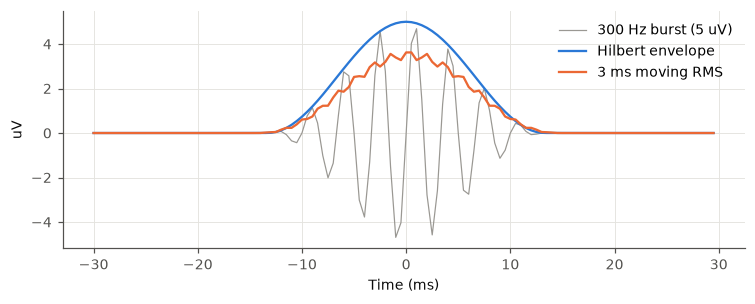

In [2]:
t = np.arange(-0.03, 0.03, 1 / FS)
burst = 5 * simulate.hfo_waveform(FS, 300.0, 8)
x = np.zeros_like(t); x[len(t)//2 - len(burst)//2 : len(t)//2 - len(burst)//2 + len(burst)] = burst
fig, ax = plt.subplots(figsize=(8, 2.8))
ax.plot(t * 1000, x, color=plotting.NEUTRAL, lw=0.8, label="300 Hz burst (5 uV)")
ax.plot(t * 1000, filters.envelope(x), color=plotting.SERIES[0], lw=1.5, label="Hilbert envelope")
ax.plot(t * 1000, filters.moving_rms(x, FS, energy_p.rms_window_ms / 1000), color=plotting.ACCENT, lw=1.5, label="3 ms moving RMS")
ax.set_xlabel("Time (ms)"); ax.set_ylabel("uV"); ax.legend(loc="upper right");

## 2. Morlet wavelets are constant-Q Gaussian band-pass filters

In the frequency domain, the wavelet at f is a Gaussian of width f / n_cycles: the relative bandwidth (1/Q) is the same at every frequency.

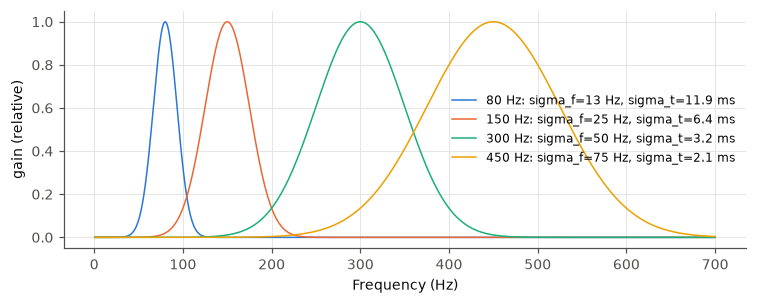

In [3]:
f_axis = np.linspace(1, 700, 2000)
fig, ax = plt.subplots(figsize=(8, 2.8))
for f0, color in zip([80, 150, 300, 450], plotting.SERIES):
    sigma_f = f0 / wavelet_p.n_cycles
    ax.plot(f_axis, np.exp(-0.5 * ((f_axis - f0) / sigma_f) ** 2), color=color, label=f"{f0} Hz: sigma_f={sigma_f:.0f} Hz, sigma_t={wavelet_p.n_cycles/(2*np.pi*f0)*1000:.1f} ms")
ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("gain (relative)"); ax.legend(fontsize=8);

## 3. Whitening tilts frequencies upwards: estimate them on the non-whitened excess

Dividing each frequency by a background scale that decreases with f (1/f) favours higher frequencies. Below we compare, on isolated HFOs, the frequency of the maximum of the whitened z-score with the frequency estimated by the detector (maximum of the non-whitened excess, refined by a parabola).

In [4]:
p = base.replace(duration_s=300.0, events={"snr_db": 15.0, "p_hfo_on_spike": 0.0, "rate_spike_per_min": 0.0})
sim = simulate.simulate_from_seed(p, 11)
det = detect_wavelet(sim.signal_uv, FS, BANDS, wavelet_p, EDGE)
hfo = sim.events.reset_index(drop=True)
dm, _ = evaluate.match_events(det, hfo)
matched = det[dm >= 0].assign(true_hz=hfo.freq_hz.to_numpy()[dm[dm >= 0]])
# Frequency of the whitened maximum (no correction), recomputed for comparison:
freqs = wavelet_p.freqs()
whitened_freq = []
for row in matched.itertuples():
    seg = sim.signal_uv[int((row.peak_s - 5) * FS): int((row.peak_s + 5) * FS)]
    amp = np.abs(morlet_transform(seg, FS, freqs, wavelet_p.n_cycles))
    med = np.median(amp, axis=1, keepdims=True); scale = 1.4826 * np.median(np.abs(amp - med), axis=1, keepdims=True)
    z = (amp - med) / scale
    c = len(seg) // 2
    band = (freqs >= 80) & (freqs <= 500)
    whitened_freq.append(freqs[band][np.argmax(z[band, c])])
matched["whitened_hz"] = whitened_freq
summary = pd.DataFrame({
    "whitened maximum": (matched.whitened_hz / matched.true_hz).describe(percentiles=[.1, .5, .9]),
    "detector estimate (excess)": (matched.freq_hz / matched.true_hz).describe(percentiles=[.1, .5, .9]),
}).loc[["count", "10%", "50%", "90%"]]
summary.round(3)

,whitened maximum,detector estimate (excess)
count,63.000,63.000
10%,0.992,1.002
50%,1.037,1.013
90%,1.093,1.033


## 4. Blob or column: the valley ratio separates oscillations from spikes

Valley ratio = min whitened z in [0.5, 0.65] x f_peak divided by z at the peak. Below: four simulated populations (300 s each).

In [5]:
base300 = base.replace(duration_s=300.0)
cases = {
    "pure-cusp spikes": base300.replace(events={**NO_EVENTS, "rate_spike_per_min": 20.0}, spike={"apex_sigma_ms": (0.0, 0.0)}),
    "calibrated spikes": base300.replace(events={**NO_EVENTS, "rate_spike_per_min": 20.0}),
    "isolated HFOs, SNR 10 dB": base300.replace(events={"rate_spike_per_min": 0.0, "p_hfo_on_spike": 0.0, "snr_db": 10.0}),
    "HFOs on spikes, SNR 10 dB": base300.replace(events={"rate_spike_per_min": 0.0, "p_hfo_on_spike": 1.0, "snr_db": 10.0}),
}
rows, ratios = [], {}
for name, params in cases.items():
    s = simulate.simulate_from_seed(params, 21)
    d = detect_wavelet(s.signal_uv, FS, BANDS, wavelet_p, EDGE, return_rejected=True)
    ev = s.events.assign(onset_s=s.events.onset_s - 0.01, offset_s=s.events.offset_s + 0.01)
    dm, rm = evaluate.match_events(d, ev)
    v = d.valley_ratio[dm >= 0].to_numpy(float)
    ratios[name] = v
    rows.append({"population": name, "events": len(ev), "with a TF peak": int((rm >= 0).sum()),
                 "median valley ratio": np.nanmedian(v), "accepted as HFO": int((v < wavelet_p.valley_ratio).sum())})
pd.DataFrame(rows).round(2)

,population,events,with a TF peak,median valley ratio,accepted as HFO
0,pure-cusp spikes,99,99,0.78,0
1,calibrated spikes,99,78,0.74,0
2,"isolated HFOs, SNR 10 dB",55,54,-0.03,54
3,"HFOs on spikes, SNR 10 dB",55,44,0.73,0


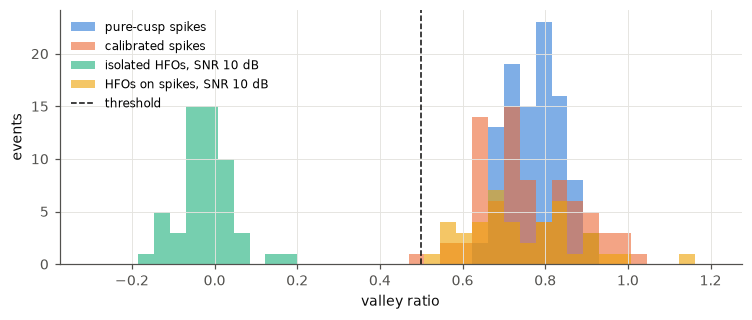

In [6]:
fig, ax = plt.subplots(figsize=(8, 3))
for (name, v), color in zip(ratios.items(), plotting.SERIES):
    ax.hist(v, bins=np.linspace(-0.3, 1.2, 40), alpha=0.6, color=color, label=name)
ax.axvline(wavelet_p.valley_ratio, color=plotting.INK, ls="--", label="threshold")
ax.set_xlabel("valley ratio"); ax.set_ylabel("events"); ax.legend(fontsize=8);

HFOs riding on a spike look like a spike column with a bump: the wavelet detector rejects them together with the spikes. This is the cost of its spike rejection, and it will be measured separately in step 4.

## 5. The three detectors on four typical situations

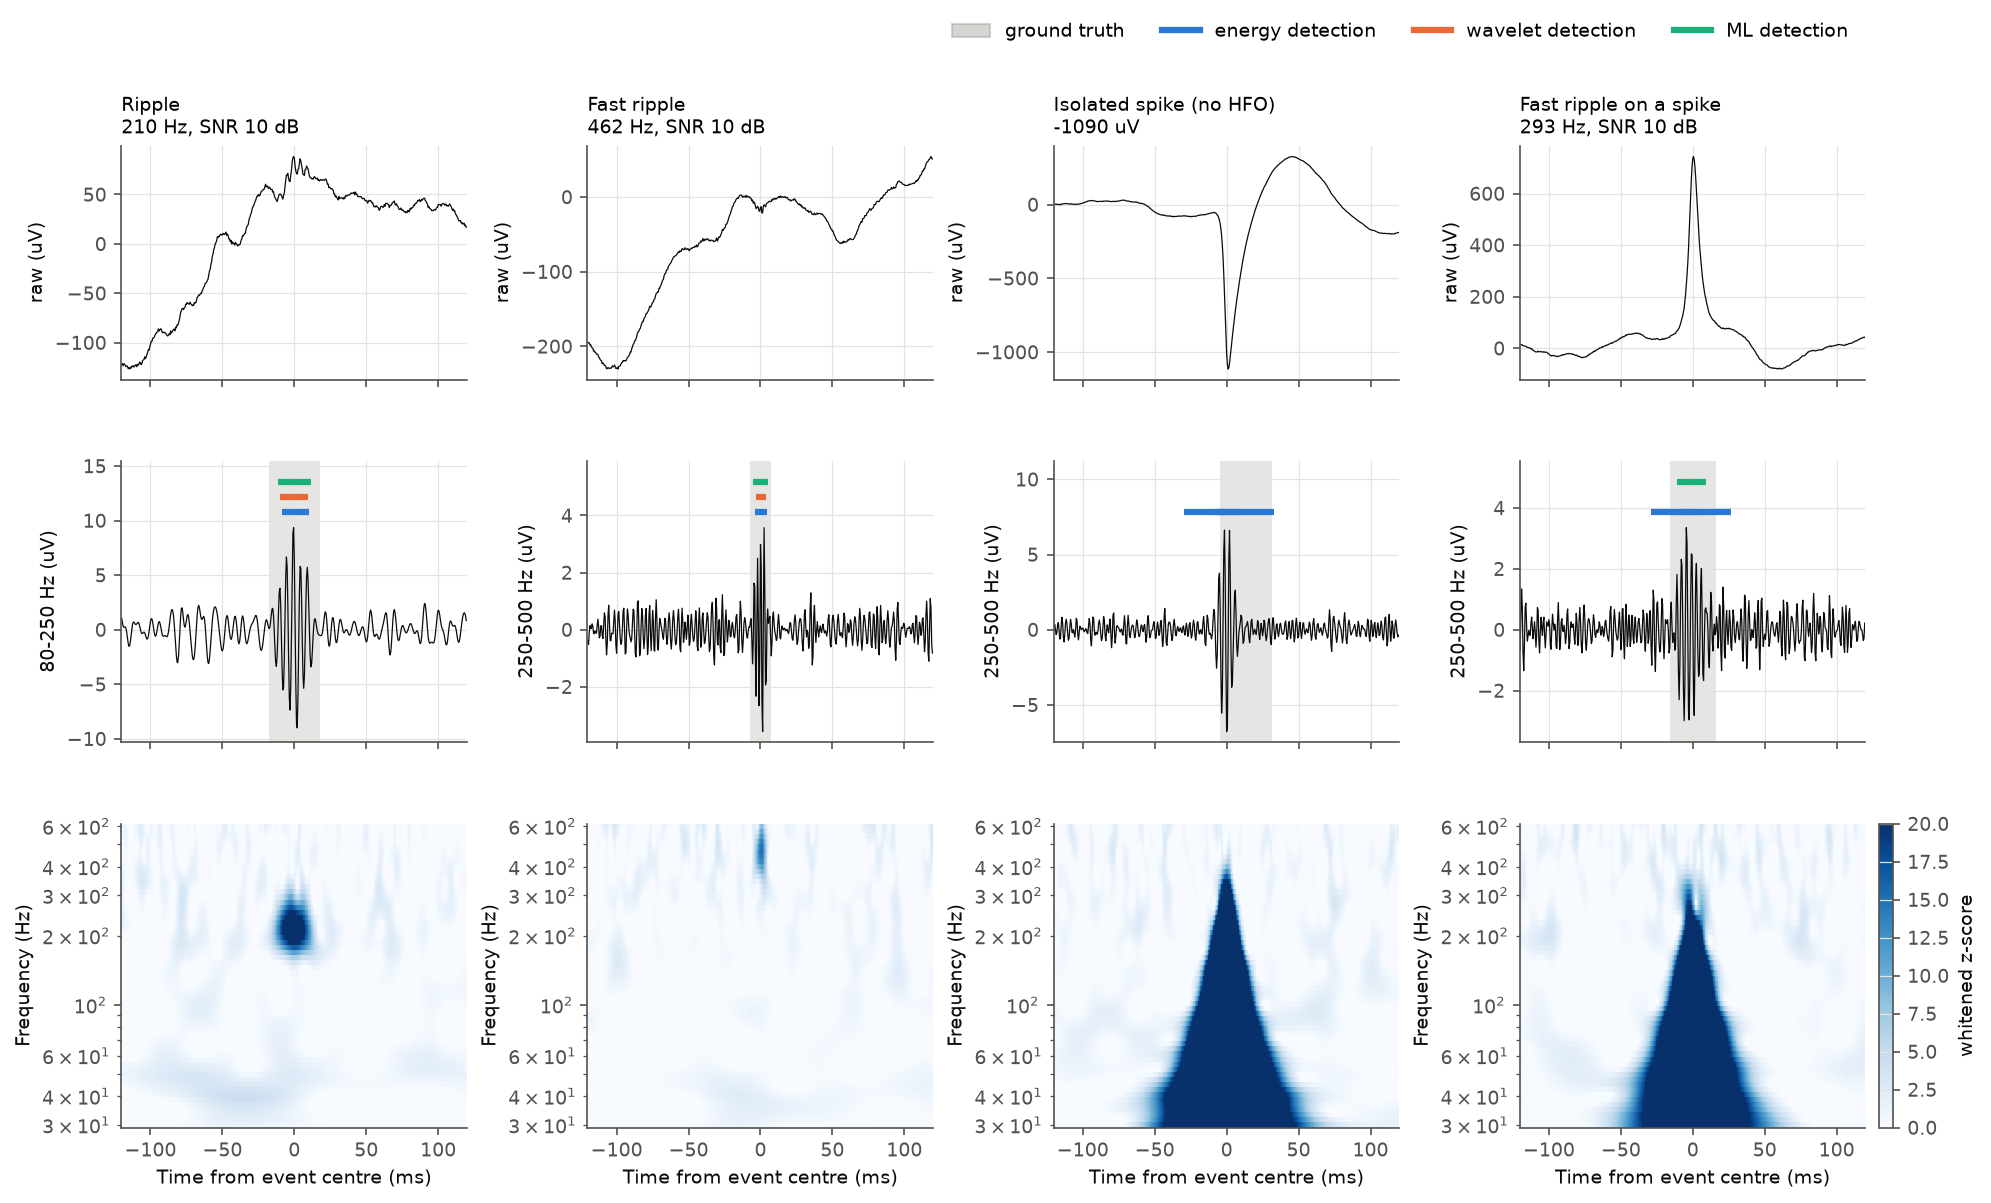

In [7]:
display(Image(filename=str(cfg["paths"]["figures_dir"] / "detector_examples.png")))

## 6. Sanity counts on one unseen simulation (SNR 10 dB)

The ML detector is trained on four other simulations (seeds 101-104, SNR 8 +/- 5 dB). Thresholds are the configuration defaults; they are tuned in step 4 on training simulations only.

In [8]:
train_p = base300.replace(events={"snr_db": 8.0, "snr_jitter_db": 5.0})
train = [simulate.simulate_from_seed(train_p, s) for s in (101, 102, 103, 104)]
ml = MLDetector(BANDS, ml_p, energy_p, wavelet_p, EDGE).fit([(s.signal_uv, s.fs, s.events) for s in train])
test = simulate.simulate_from_seed(base300, 999)
dets = {"energy": detect_energy(test.signal_uv, FS, BANDS, energy_p, EDGE),
        "wavelet": detect_wavelet(test.signal_uv, FS, BANDS, wavelet_p, EDGE),
        "ML": ml.detect(test.signal_uv, FS)}
rows = []
for name, d in dets.items():
    for band in BANDS:
        c = evaluate.count_matches(d[d.band == band], test.events[test.events.kind == band])
        rows.append({"detector": name, "band": band, **c})
pd.DataFrame(rows).pivot(index="detector", columns="band")

tp                 fp                 fn       
band     fast_ripple ripple fast_ripple ripple fast_ripple ripple
detector                                                         
ML                20     22           4      0           4     10
energy            10     19           6     24          14     13
wavelet           19     21           1      0           5     11

In [9]:
ml.feature_importances().sort_values("fast_ripple", ascending=False).round(3)

,fast_ripple,ripple
freq_hz,0.206,0.107
tf_peak_z,0.168,0.106
energy_ratio_db,0.163,0.123
envelope_peak_z,0.120,0.145
line_length_ratio,0.074,0.087
tf_valley_ratio,0.068,0.137
low_band_ratio_db,0.052,0.078
sharpness_z,0.048,0.058
raw_amplitude_z,0.041,0.111
duration_ms,0.033,0.034


## 7. Notch filter decision (real data)

From `results/notch_decision.csv` (`scripts/06_notch_decision.py`): detections on the raw and on the notch-filtered signal, for channels with mains harmonics inside the HFO bands.

In [10]:
notch = pd.read_csv(cfg["paths"]["results_dir"] / "notch_decision.csv")
s = notch.groupby("detector")[["n_raw", "n_notched", "locked_raw", "locked_notched"]].sum()
s["locked_raw_%"] = 100 * s.locked_raw / s.n_raw
s["locked_notched_%"] = 100 * s.locked_notched / s.n_notched
s.round(1)

,n_raw,n_notched,locked_raw,locked_notched,locked_raw_%,locked_notched_%
detector,,,,,,
energy,16324,17222,1331,925,8.2,5.4
wavelet,4937,4754,334,264,6.8,5.6


## 8. Take-aways

* **Energy**: simple and sensitive at high SNR, but fooled by sharp spikes, especially in the ripple band, where a spike's spectrum is much stronger.
* **Wavelet**: whitening makes weak fast ripples visible, and the valley test rejects spikes, at the price of rejecting HFOs that ride on spikes. Its frequency must be estimated on the non-whitened map.
* **ML**: learns to reject spikes while keeping part of the HFOs on spikes. Its most important fast-ripple feature is the frequency, which may partly reflect a simulator property (spikes ring near the lower band edge): to check on real data in step 4.
* No notch filter in the main analysis: mains harmonics cause only ~1-3 % extra detections, and a notch shifts the energy threshold differently in each recording.